# Project: Loan Eligibility Prediction using Machine Learning

## 1. The Business Problem
This project uses historical loan decisions to classify applications as approved or rejected. The Kaggle data available here does not contain repayment or default outcomes, so this is loan-approval prediction, not default-risk prediction.

**Objective:** Build and evaluate a binary classifier using applicant information such as income, credit score, assets, and dependents. Its output estimates the historical `loan_status` label and should support, not replace, a lender's decision process.

## 2. The Data Science Challenge
From a data science perspective, this is a classic **Supervised Machine Learning** problem. 

Specifically, it is a **Binary Classification** challenge. The target variable `loan_status` has two outcomes: **"Approved" (1)** and **"Rejected" (0)**. This target does not identify whether an approved borrower later defaults.

**Key challenges we will address in this project:**
*   Checking missing values, duplicate rows, and unusual numeric values. Unusual asset values are reviewed rather than automatically deleted because they may be valid.
*   Encoding categorical features (like Education and Self_Employed) into numerical formats.
*   Addressing potential Class Imbalance using techniques like SMOTE (Synthetic Minority Oversampling Technique).
*   Comparing Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, and XGBoost using cross-validation, ROC-AUC, and MCC.

Import the packages and libraries needed for data preprocessing, visualization, and model building.

In [1]:
import pandas as pd
import numpy as  np
import matplotlib.pyplot as plt
import seaborn as sns


Load the dataset and perform initial exploratory data analysis (EDA) to understand the distribution of features, identify correlations, and visualize patterns that may inform feature engineering and model selection.

In [2]:
loan_data = pd.read_csv('D:\\Loan Default Risk Analysis\\data\\loan_approval_dataset.csv', skipinitialspace=True)
loan_data.columns = loan_data.columns.str.strip()
print(f"Exact duplicate rows: {loan_data.duplicated().sum()}")
loan_data = loan_data.drop_duplicates().copy()
print("Missing values by column:")
display(loan_data.isna().sum())
loan_data.head()

Exact duplicate rows: 0
Missing values by column:


loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


Descriptive Statistics 

Data types -> It is important to check the data types of each column in the dataset. This will help us identify which columns are numerical and which are categorical, allowing us to apply appropriate preprocessing techniques.


In [3]:
loan_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amount               4269 non-null   int64
 6   loan_term                 4269 non-null   int64
 7   cibil_score               4269 non-null   int64
 8   residential_assets_value  4269 non-null   int64
 9   commercial_assets_value   4269 non-null   int64
 10  luxury_assets_value       4269 non-null   int64
 11  bank_asset_value          4269 non-null   int64
 12  loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 519.1 KB


Statistical Summary -> We will generate a statistical summary of the numerical features in the dataset. This summary will include measures such as mean, median, standard deviation, minimum, and maximum values. It will help us understand the central tendency and variability of the data.


In [5]:
loan_data.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


Removing the extra spaces and special characters from the column names to ensure consistency and avoid potential issues during data manipulation and modeling.

In [6]:
loan_data.columns = loan_data.columns.str.strip().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')
loan_data.columns

Index(['loan_id', 'no_of_dependents', 'education', 'self_employed',
       'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
       'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value', 'loan_status'],
      dtype='str')

In [7]:
loan_id = loan_data.drop(columns=['loan_id'])
loan_id

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


Check missing values and IQR-flagged values. This Kaggle file has no missing values or exact duplicate rows. Potential asset-value outliers are flagged for review, not automatically removed, because valid high-value financial records should not be discarded without evidence. The training pipeline median-imputes future missing numeric values.

In [8]:
print("Missing values by column:")
display(loan_data.isna().sum())

numeric_columns = loan_data.select_dtypes(include="number").columns.drop("loan_id", errors="ignore")
outlier_counts = {}
for column in numeric_columns:
    q1, q3 = loan_data[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_counts[column] = int(((loan_data[column] < q1 - 1.5 * iqr) | (loan_data[column] > q3 + 1.5 * iqr)).sum())
pd.Series(outlier_counts, name="IQR-flagged values").sort_values(ascending=False)

Missing values by column:


loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

residential_assets_value    52
commercial_assets_value     37
bank_asset_value             5
no_of_dependents             0
income_annum                 0
cibil_score                  0
loan_term                    0
loan_amount                  0
luxury_assets_value          0
Name: IQR-flagged values, dtype: int64

Visulization of the data -> We will create visualizations to explore the relationships between features and the target variable. This will help us identify patterns, trends, and potential predictors of loan approval.


C:\Users\ashwa\AppData\Local\Temp\ipykernel_33268\4233452405.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='loan_status', data=loan_data, palette='Set2')
C:\Users\ashwa\AppData\Local\Temp\ipykernel_33268\4233452405.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='loan_status', y='cibil_score', data=loan_data, palette='Set2')


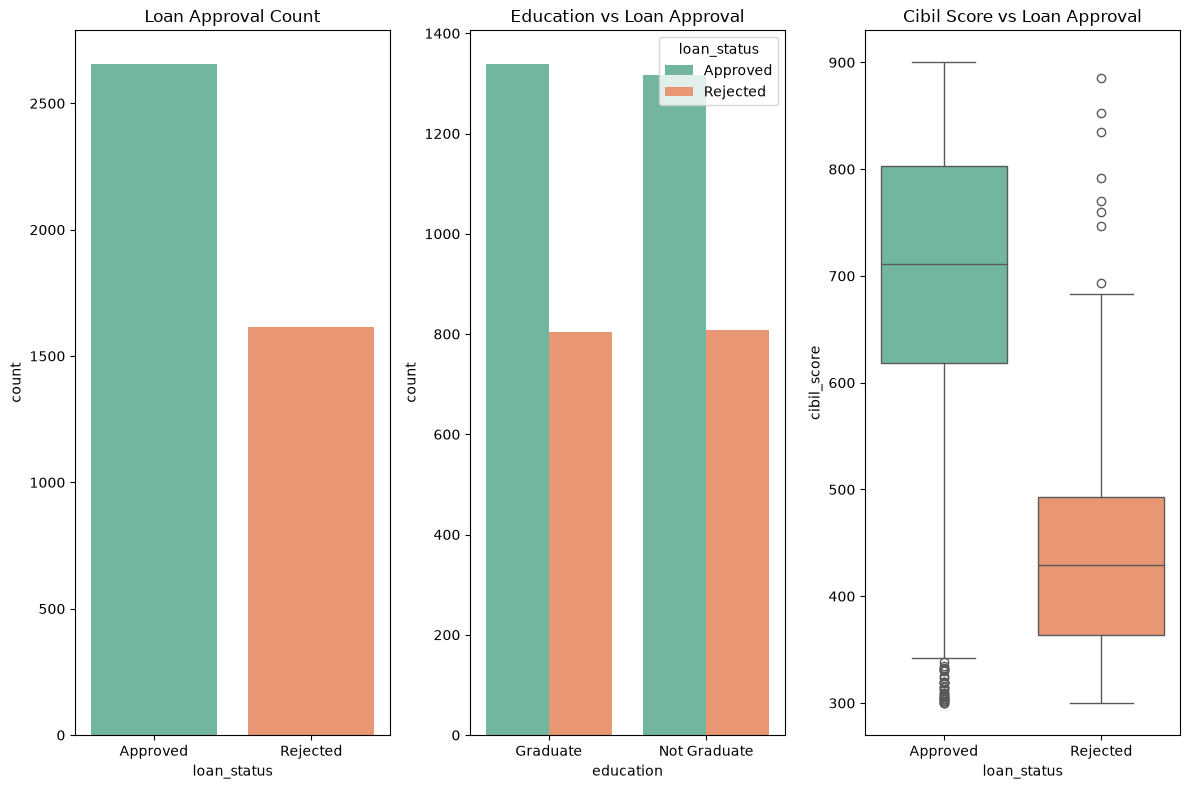

In [9]:
plt.figure(figsize=(12, 8))
plt.subplot(1,3,1)
sns.countplot(x='loan_status', data=loan_data, palette='Set2')
plt.title('Loan Approval Count')
# education (gradate/not gradate) effect on loan approval
plt.subplot(1,3,2)
sns.countplot(x='education', hue='loan_status', data=loan_data, palette='Set2')
plt.title('Education vs Loan Approval')
#cibil score effect on loan approval
plt.subplot(1,3,3)
sns.boxplot(x='loan_status', y='cibil_score', data=loan_data, palette='Set2')
plt.title('Cibil Score vs Loan Approval')
plt.tight_layout()
plt.show()

Feature Engineering -> We will create new features or transform existing ones to improve the predictive power of our models. This may include creating interaction terms, scaling numerical features, or encoding categorical variables.

In [10]:
loan_data['loan_status'] = loan_data['loan_status'].map({'Approved': 1, 'Rejected': 0})
# Education 
loan_data['education'] = loan_data['education'].map({'Graduate': 1, 'Not Graduate': 0}) 

#self employed
loan_data['self_employed'] = loan_data['self_employed'].map({'Yes':1,'No':0})
display(loan_data.head())

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,2,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,4,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0


In [11]:
# save the cleaned and preprocessed data to a new CSV file
loan_data.to_csv('D:\\Loan Default Risk Analysis\\data\\loan_approval_dataset_cleaned.csv', index=False)
